# DES Y3: what does three-point shear add to intrinsic-alignment constraints?

A smaller joint error is meaningful only if the comparison retains the same
cosmological and nuisance parameters, the same priors, and the correlations between
both measurements. This notebook builds that comparison from the full selected
$\xi_\pm$ vector and the third-order aperture statistic $\langle M_{\rm ap}^3\rangle$.
It uses the project wrappers and the compiled CosmoLike calculations, as the LSST Y1
notebooks do. The YAML records the physical model and numerical choices; the notebook
explains their meaning and displays the results.

**Execution record.** The saved notebook executes only input verification, public
covariance inspection, and a small controlled IA response. It does not contain an
executed DES forecast or a measured improvement in parameter errors. The three
production switches below are false. Their cells become executable when deliberately
turned on in a suitable compute environment; the CLI provides the same calculation.

**Scientific status.** [The TATT YAML](configs/des_y3_tatt_fisher.yaml) is a new
forecast design using public simulated Y3 inputs. It retains all 400 two-point and
80 aperture entries. The published two-point scale cuts are not applied, and exact
agreement between the finite-triangle mean and covariance estimator remains
unvalidated. These choices must be resolved before a DES inference claim. Read
[PAPER_TARGETS.md](PAPER_TARGETS.md) for the distinction between reproducing
[the NLA methods paper](https://arxiv.org/abs/2503.03964) and testing the IA mechanisms
in [the TATT paper](https://arxiv.org/abs/2601.09133).

## 1. Keep numerical ownership visible

Run this notebook from the `des_3pcf` project directory in Cocoa's Python environment.
The setup sets BLAS workers to one before importing NumPy or plotting libraries.
It also limits and verifies any BLAS pool already loaded in the running kernel
through the public `threadpoolctl` API; environment variables alone cannot resize it.
The small demonstration uses one OpenMP worker. Production worker counts come from
the YAML and are restricted to one through four. The wrapper launches a production
command in a separate process, so it cannot inherit an incompletely configured
ordinary two-point module from an earlier notebook cell.

In [1]:
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS", "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
PROJECT = Path.cwd()
if not (PROJECT / "PAPER_TARGETS.md").is_file():
    raise ValueError("Open this notebook with des_3pcf as the working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))

import numpy as np
import cosmolike_des_3pcf_fisher_wrappers as nw
plots = importlib.import_module("cosmolike_notebook_utils.3pcf")
from threadpoolctl import threadpool_info, threadpool_limits
# Environment variables cannot resize a BLAS pool already loaded by this kernel.
# Keep this public controller alive so later notebook matrix calls remain serial.
BLAS_LIMIT = threadpool_limits(limits=1, user_api="blas")
for pool in threadpool_info():
    if pool["user_api"] == "blas" and pool["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS pool did not accept its one-worker limit.")
workflow = nw.FisherWorkflow(configuration=PROJECT / "configs/des_y3_tatt_fisher.yaml")

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams['figure.dpi'] = 90


## 2. What the requested experiment contains

The configuration varies five cosmological parameters, five intrinsic-alignment
parameters in the tidal-alignment and tidal-torquing (TATT) model, and eight
calibration/source-redshift parameters. TATT describes correlations between
intrinsic galaxy shape and the tidal gravitational field. $A_1$ multiplies linear
alignment; $A_2$ multiplies a quadratic tidal operator; $b_{\rm TA}$ controls density
weighting of the aligned sample. The two exponents $\eta_1,\eta_2$ allow those
amplitudes to evolve with redshift. Nonzero fiducial amplitudes are deliberate:
at zero amplitude, its redshift exponent has a zero derivative and cannot be
constrained by a local Fisher calculation.

The YAML fixes velocity shear and the bispectrum feedback amplitude to zero.
CFASTPT evaluates the perturbative convolution integrals used by the existing
two-point model. That model does not supply a joint response for either choice. Allowing the three-point mean alone to vary a feedback parameter while
silently holding its two-point response fixed would define a different, incomplete
physical experiment. This notebook therefore forecasts IA, and leaves a joint
baryonic-feedback forecast pending a common power/bispectrum prescription.

The Gaussian prior widths apply to the four multiplicative calibrations and four
source-redshift shifts. They enter each reported posterior exactly once. A quoted
uniform prior range is not converted into a Gaussian standard deviation. The
configuration's bounds only ensure that the finite-difference stencil stays in its
specified parameter domain. The inspection below performs no mean calculation.

In [3]:
inspection = workflow.inspect(command="fisher")
print(inspection["description"])
print("Parameters:", inspection["varied_parameters"])
print("Distinct means for h and h/2:", inspection["distinct_mean_evaluations"])
print("Gaussian prior sigmas:", inspection["gaussian_prior_sigmas"])
print("Missing execution inputs:", inspection["missing_inputs"])

DES Y3 joint xi± + Map3 TATT Fisher design using all 480 public rows; estimator and scale validity remain unvalidated.
Parameters: ['omega_m', 'sigma8', 'omega_b', 'h', 'ns', 'a1', 'eta1', 'a2', 'eta2', 'bta', 'm1', 'm2', 'm3', 'm4', 'dz1', 'dz2', 'dz3', 'dz4']
Distinct means for h and h/2: 109
Gaussian prior sigmas: {'m1': 0.0091, 'm2': 0.0078, 'm3': 0.0076, 'm4': 0.0076, 'dz1': 0.018, 'dz2': 0.015, 'dz3': 0.011, 'dz4': 0.017}
Missing execution inputs: [{'input': 'physics tables', 'path': '/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/y3_tatt_physics.npz'}]


## 3. Check the actual public inputs and cross-covariance

A filename is not a provenance check. The manifest records Git blob identifiers at
one upstream commit; the following helper compares the downloaded bytes with those
identifiers. It does not download anything. If files are absent, run the project's
explicit fetch script before this section.

The covariance has three visible blocks: $\xi_+$, $\xi_-$ and aperture moments. Its
color plot divides each element by the square root of the corresponding two
variances, producing a dimensionless correlation coefficient. Small cross-block
entries are still retained. The low cut near eight arcminutes in the methods paper
acts on **both side–angle–side (SAS) triangle length parameters**, not on the aperture radii and not on
an additional third-side cut. The new YAML uses an explicit approximate 8–80 arcmin
side grid; the exact retained measured bin edges and averaging still need a direct
operator comparison. In particular, labeling both calculations `finite_sas` does
not establish equality of their estimators.

In [4]:
provenance = nw.verify_public_inputs()
print(provenance["repository"], provenance["commit"])
print("Pinned files verified:", sum(
    record["status"] == "matches_pinned_blob" for record in provenance["files"]
), "/", len(provenance["files"]))
rows, covariance, counts = workflow.public_covariance()
print("Rows:", counts)
print("Nonzero xi–Map3 covariance cells:", np.count_nonzero(covariance[:400, 400:]))

https://github.com/rchgomes/3pcf_integrator d6098d326dcb03bc750adcc9627119f52d928944
Pinned files verified: 12 / 12
Rows: {'xip': 200, 'xim': 200, 'map3': 80}
Nonzero xi–Map3 covariance cells: 32000


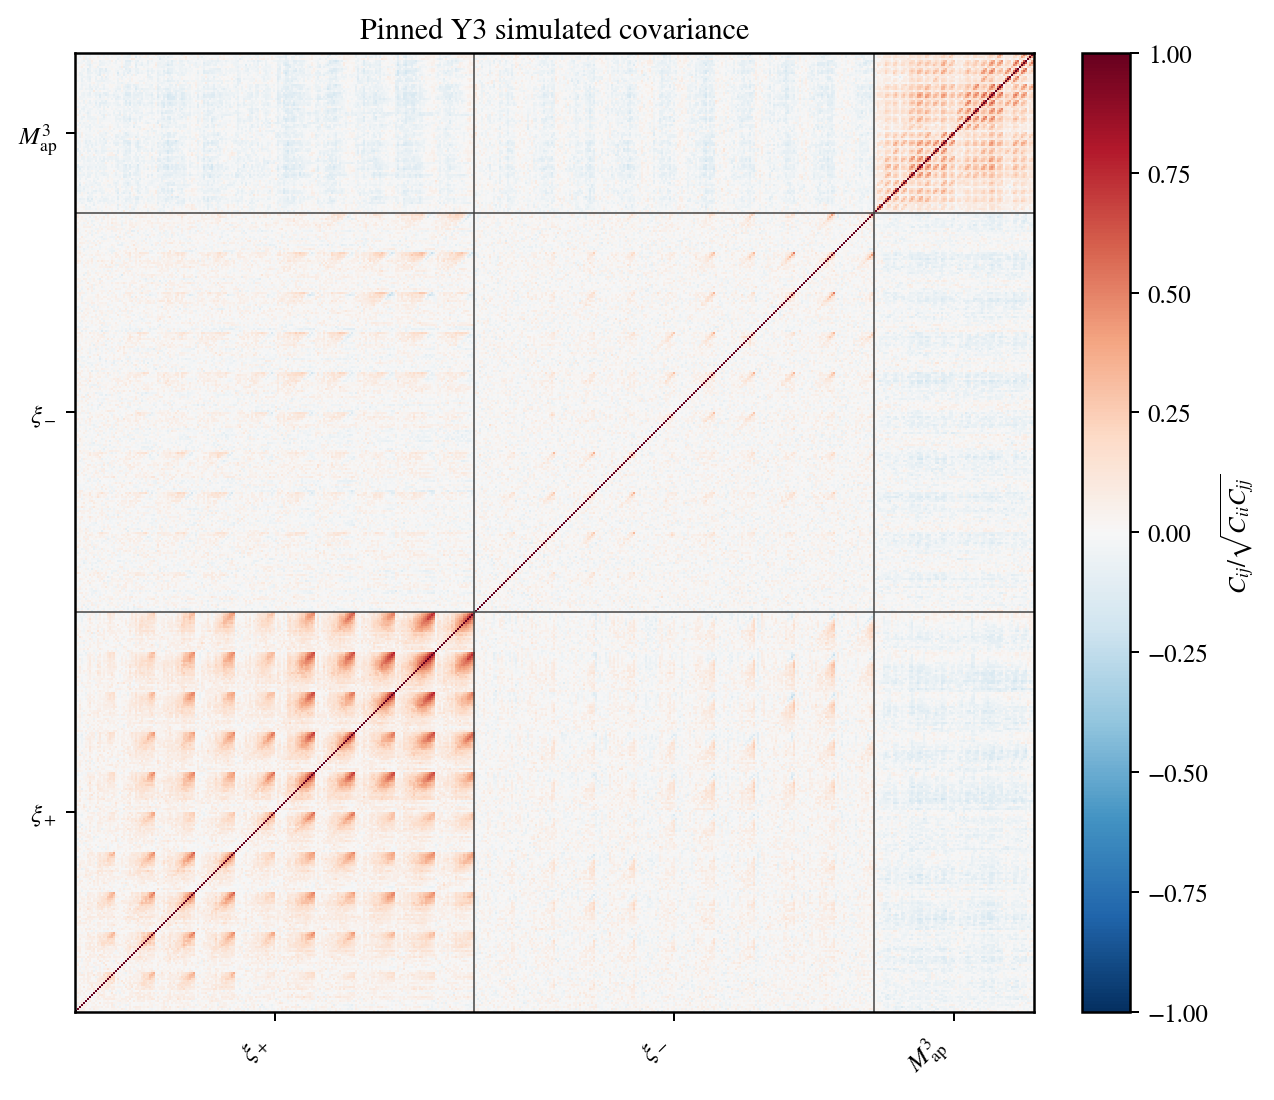

In [5]:
plots.plot_correlation(
    covariance=covariance, block_sizes=[200, 200, 80],
    labels=("Pinned Y3 simulated covariance", "Reference"),
    block_labels=[r"$\xi_+$", r"$\xi_-$", r"$M_{\rm ap}^3$"], show=1,
)

## 4. A bounded IA mechanism demonstration

A sign reversal of two IA amplitudes need not reverse the complete observed signal:
gravity, linear alignment, quadratic alignment and their products enter differently.
The small calculation below makes that statement inspectable. It evaluates twelve
equilateral angular triangles for two source samples, using smooth controlled input
power and distance tables. A bispectrum measures correlations of three Fourier modes whose wavevectors
close into a triangle; equilateral means their lengths are equal. The outputs
here are projected bispectra, not measured DES aperture moments. The source curves and background are teaching inputs and cannot
be used to quote survey constraints.

The first figure keeps the sign of the physical prediction. The second compares
with the no-IA curve after division by one fixed reference scale per source panel; it never divides
by a signal that may pass through zero. The two nonzero amplitude choices echo a
sign-degeneracy example in the TATT paper, but this is not a reproduction of that
paper's Figure 9, which uses different observables and survey inputs.

Controlled inputs; no DES inference or accuracy claim.


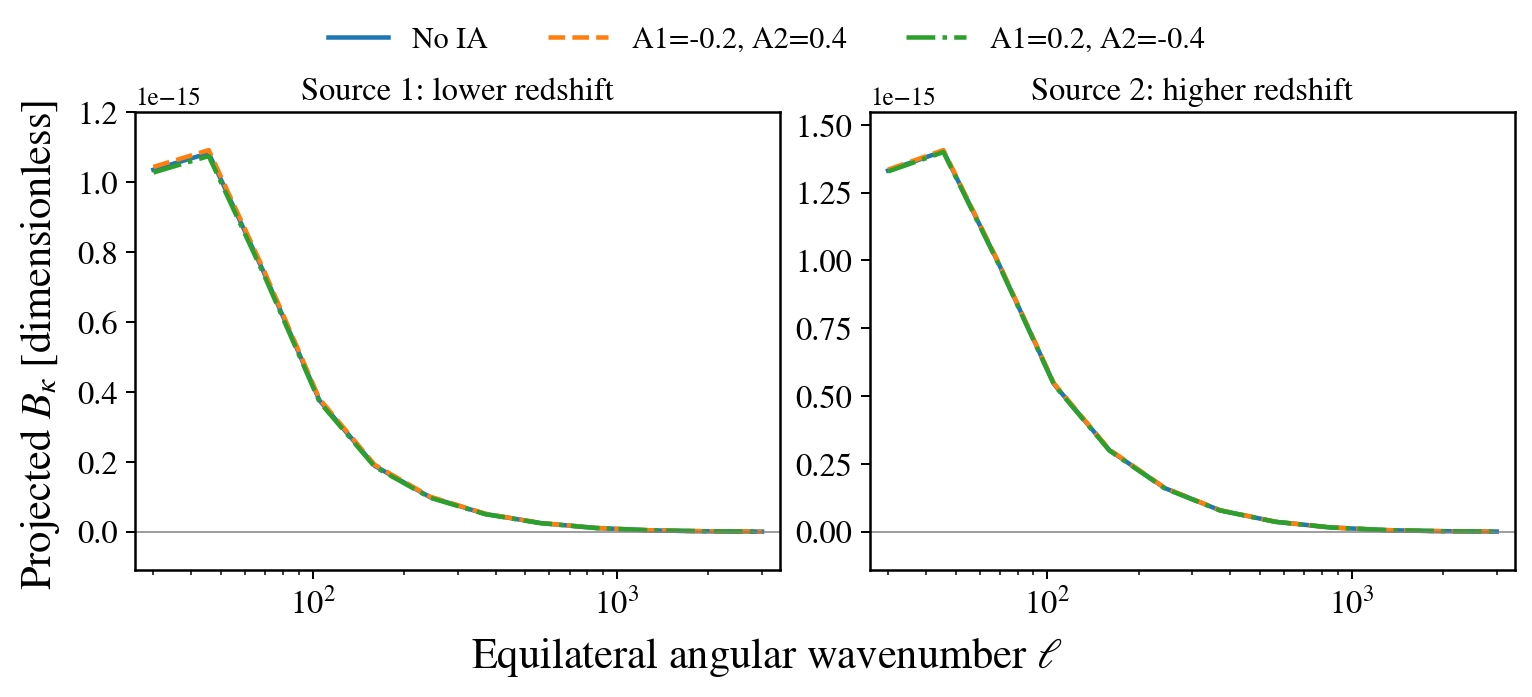

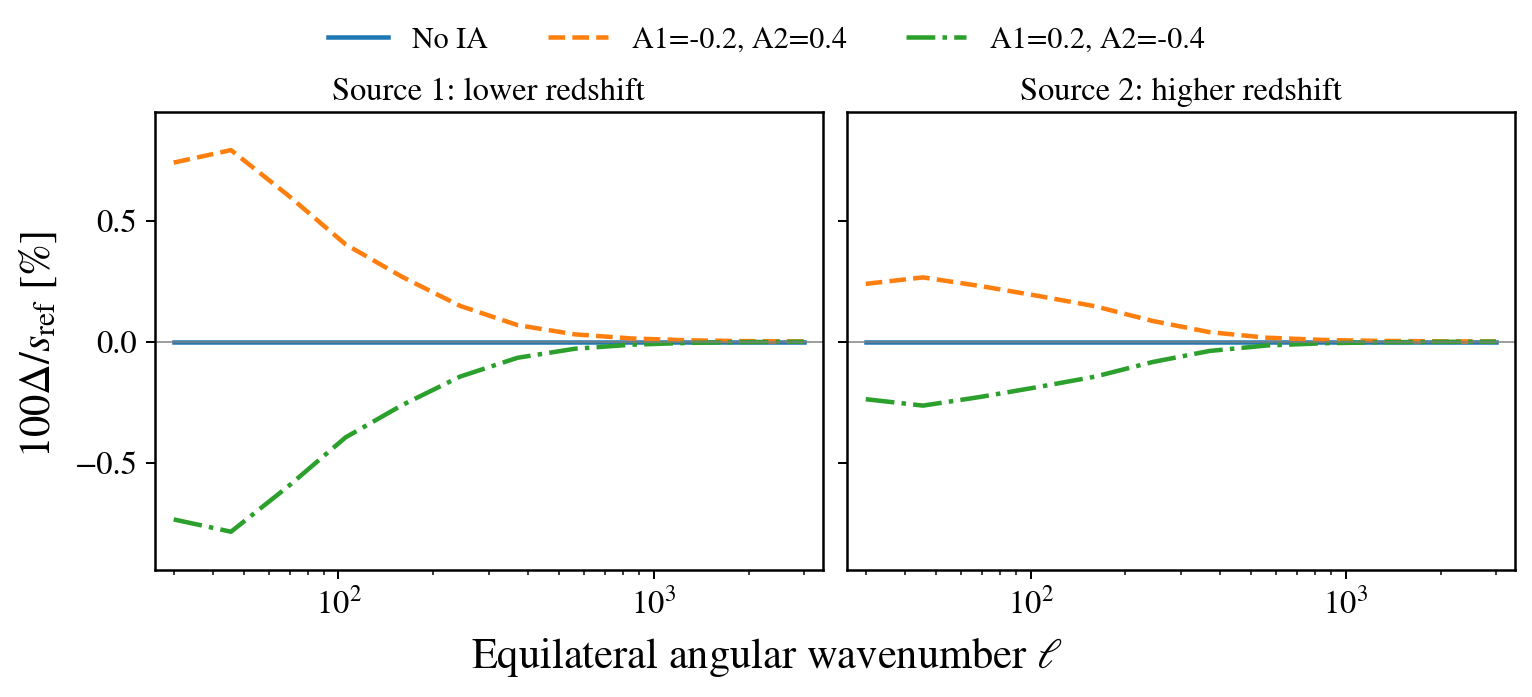

In [6]:
demonstration = nw.controlled_ia_response(power_mode=2, threads=1)
print(demonstration["interpretation"])
curves = []
for signal in demonstration["signals"]:
    curves.append((demonstration["ell"], signal))
plots.plot_ia_components(
    components=curves,
    component_labels=["Source 1: lower redshift", "Source 2: higher redshift"],
    coordinate_label=r"Equilateral angular wavenumber $\ell$",
    quantity_label=r"Projected $B_\kappa$ [dimensionless]",
    legend=demonstration["labels"], ncols=2, bintextpos=None,
    bintextsize=13, legendfontsize=12, show=1,
)
plots.plot_ia_components(
    components=curves, components_ref=curves[0],
    component_labels=["Source 1: lower redshift", "Source 2: higher redshift"],
    coordinate_label=r"Equilateral angular wavenumber $\ell$",
    quantity_label=r"Projected $B_\kappa$ [dimensionless]",
    legend=demonstration["labels"], residual="scaled", ncols=2,
    bintextpos=None, bintextsize=13, legendfontsize=12, show=1,
)

## 5. Why the information comparison conditions on the two-point data

For a parameter vector $p$, write the derivative matrix as
$D_{i\alpha}=\partial\mu_i/\partial p_\alpha$, with one row per observable.
With a fixed covariance $C$, the Gaussian likelihood information is
$F=D^{\mathsf T}C^{-1}D$. Two observables can respond differently to parameters
and nevertheless share noise. The question is how much of the three-point response
is still informative after the two-point vector is known.

Partition the data into two- and three-point rows. Define

$$C_{3|2}=C_{33}-C_{32}C_{22}^{-1}C_{23},\qquad
D_{3|2}=D_3-C_{32}C_{22}^{-1}D_2.$$

Then

$$F_{\rm joint,like}=F_{2,\rm like}
+D_{3|2}^{\mathsf T}C_{3|2}^{-1}D_{3|2}.$$

The second term is the added three-point information. It can be small even when
$D_3$ is large, because the corresponding response may already be predicted by
$\xi_\pm$. The code tests this identity on an explicit correlated counterexample.
It obtains $F_2$ by selecting $C_{22}$ **before inversion**; selecting a block of
$C^{-1}$ would instead condition on the discarded three-point measurements.
A prior matrix is then added once to $F_2$ and once to $F_{\rm joint}$ for the two
posterior comparisons. It is not added to the conditional information term.

## 6. Execute the full experiment explicitly

The next cells are the production workflow. Preparation builds physical tables from
CAMB and the public source distributions. Evaluation checks the complete mean before
requesting its derivatives. The Fisher calculation evaluates both fourth-order
stencils, with steps $h$ and $h/2$, and holds the full covariance fixed. It does not
compress the two-point vector, run a posterior sampler, or include covariance
parameter derivatives. An existing output is preserved unless `overwrite=True`
is explicitly passed.

The saved notebook leaves all three switches false. The equivalent shell commands,
from this project directory in the activated Cocoa environment, are:

```bash
python scripts/run_3pcf.py prepare configs/des_y3_tatt_fisher.yaml
python scripts/run_3pcf.py evaluate configs/des_y3_tatt_fisher.yaml
python scripts/run_3pcf.py fisher configs/des_y3_tatt_fisher.yaml
```

The preparation path is shared with the optional
[NLA comparison YAML](configs/des_y3_nla_fisher.yaml). That comparison fixes the
quadratic IA parameters and removes their derivative columns. It is conditional on
a simpler physical model, so smaller errors there cannot be attributed to a better
measurement alone. The core TATT accuracy controls, projection grids and transform
settings are written explicitly in both YAML files.

In [7]:
RUN_SURVEY_PREPARATION = False
RUN_SURVEY_MEAN = False
RUN_SURVEY_FISHER = False

In [8]:
if RUN_SURVEY_PREPARATION:
    print(workflow.run(command="prepare"))
else:
    print("CAMB survey preparation has not been executed in this notebook.")

CAMB survey preparation has not been executed in this notebook.


In [9]:
if RUN_SURVEY_MEAN:
    print(workflow.run(command="evaluate"))
else:
    print("The full 480-row survey mean has not been executed.")

The full 480-row survey mean has not been executed.


In [10]:
if RUN_SURVEY_FISHER:
    print(workflow.run(command="fisher"))
else:
    print("The DES Y3 Fisher forecast has not been executed; no survey errors exist.")

The DES Y3 Fisher forecast has not been executed; no survey errors exist.


## 7. Read and interpret a completed Fisher run

The result includes both derivative stencils, joint and two-point likelihood
information, the conditional three-point information, and the one prior matrix.
Marginalized errors come from the inverse parameter information after retaining all
other varied parameters. If a direction is unresolved, the file records a rank
diagnostic rather than substituting a pseudoinverse. A file from a different YAML
digest is refused; editing a notebook cannot silently relabel old output.

Once the production run exists, turn on the switch below. The error-ratio plot uses
$\sigma_{\rm joint}/\sigma_{2}$: values below one indicate a reduction in the local
marginalized uncertainty. Check the saved derivative-step comparison, refine the
physical/transform grids independently, and test declared angular selections before
interpreting such a reduction as robust IA information. A numerical response plot
alone does not validate the nonlinear IA continuation or the reused covariance.

In [11]:
READ_SURVEY_RESULT = False
if READ_SURVEY_RESULT:
    result, metadata = workflow.load_result(command="fisher")
    print("Rank checks:", metadata["comparison_rank_status"])
    print("h versus h/2 derivative change:", result["derivative_relative_change"])
    if "sigma_joint" in result and "sigma_two_point" in result:
        plots.plot_parameter_errors(
            names=list(result["parameter_names"]),
            errors=[result["sigma_two_point"], result["sigma_joint"]],
            errors_ref=result["sigma_two_point"],
            legend=["Two-point + priors", "Joint + the same priors"], show=1,
        )
else:
    print("No production Fisher result loaded or plotted.")

No production Fisher result loaded or plotted.


## 8. What would justify a scientific conclusion?

A convincing IA result requires a stable added-information direction, not merely a
large derivative. Repeat the complete comparison with refined quadrature and
interpolation, then with explicit small-scale selections and the alternative
three-point IA power prescriptions. Retain the same prior matrix in each comparison.
Inspect whether the inferred improvement survives marginalizing the source-redshift
and calibration parameters. The public covariance was produced for a particular
fiducial simulation and estimator; using it for a TATT mean is a stated approximation
whose effect still needs a model or mock test.

The NLA methods paper reports only about 3% tightening of its alignment-amplitude
posterior; the TATT paper does not supply a quantified IA Fisher improvement.
A larger gain in this new forecast must therefore be demonstrated and validated,
not assumed from either paper.

The present bispectrum feedback parameter is insufficient for a joint baryonic
forecast because it does not define the corresponding two-point power response.
The methods paper used baryon-contaminated signals to test scale robustness; that
exercise does not by itself establish a measured constraint on feedback parameters.
A future joint feedback study must name one common physical prescription for both
power and bispectrum, specify its interaction with IA, and validate the same cuts.
No such survey constraint or reproduction claim is inferred from the executed
controlled demonstration above.